In [ ]:
# ===== 1. Setup & configuration =====
import os, random, copy, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import cv2
import matplotlib.pyplot as plt, seaborn as sns
from glob import glob
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision import transforms
from torchvision.models import (efficientnet_b3, EfficientNet_B3_Weights,
                                efficientnet_v2_s, EfficientNet_V2_S_Weights)
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             recall_score, classification_report, confusion_matrix)
from google.colab import drive

warnings.filterwarnings("ignore")
cv2.setNumThreads(0)
drive.mount("/content/drive")

# ---- paths (same split CSVs as the whole team) ----
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/HAM10000"
SAVE_DIR = "/content/drive/MyDrive/HAM10000_Project"      # checkpoints + results are saved here
os.makedirs(SAVE_DIR, exist_ok=True)

# ---- hyper-parameters ----
IMG          = 300      # input size (EfficientNet-B3 native resolution)
EPOCHS       = 30
WARMUP       = 2        # epochs of linear LR warm-up before cosine decay
BATCH        = 32
PATIENCE     = 8        # early stopping on validation macro-F1
TARGET       = 1200     # images per class per epoch (big classes undersampled, small oversampled)
LR_BACKBONE  = 2e-4
LR_HEAD      = 1e-3
WEIGHT_DECAY = 1e-4
FOCAL_GAMMA  = 2.0
LABEL_SMOOTH = 0.05
EMA_DECAY    = 0.998
USE_HAIR_REMOVAL    = True
USE_COLOR_CONSTANCY = True

# ---- ensemble: (backbone, seed). Training skips any model whose checkpoint already exists ----
ENSEMBLE = [("b3", 42), ("b3", 7), ("v2_s", 123)]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


Mounted at /content/drive
Device: cuda


In [ ]:
# ===== 2. Load the shared train / val / test splits =====
train_df = pd.read_csv(os.path.join(BASE_DIR, "train_split.csv"))
val_df   = pd.read_csv(os.path.join(BASE_DIR, "val_split.csv"))
test_df  = pd.read_csv(os.path.join(BASE_DIR, "test_split.csv"))

image_paths = (glob(os.path.join(BASE_DIR, "HAM10000_images_part_1", "*.jpg")) +
               glob(os.path.join(BASE_DIR, "HAM10000_images_part_2", "*.jpg")))
image_map = {os.path.splitext(os.path.basename(p))[0]: p for p in image_paths}

for d in (train_df, val_df, test_df):
    d["path"] = d["image_id"].map(image_map)
    assert d["path"].notna().all(), "some images were not found"

class_names  = sorted(train_df["dx"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
num_classes  = len(class_names)
MEL = class_to_idx["mel"]

# no lesion may appear in two splits (prevents leakage)
assert not (set(train_df.lesion_id) & set(val_df.lesion_id))
assert not (set(train_df.lesion_id) & set(test_df.lesion_id))
assert not (set(val_df.lesion_id) & set(test_df.lesion_id))

print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))
print(train_df["dx"].value_counts())


Train / Val / Test: 7991 1008 1016
dx
nv       5369
mel       877
bkl       856
bcc       424
akiec     260
vasc      108
df         97
Name: count, dtype: int64


caching train:   0%|          | 0/7991 [00:00<?, ?it/s]

caching val:   0%|          | 0/1008 [00:00<?, ?it/s]

caching test:   0%|          | 0/1016 [00:00<?, ?it/s]

(7991, 300, 300, 3) (1008, 300, 300, 3) (1016, 300, 300, 3)


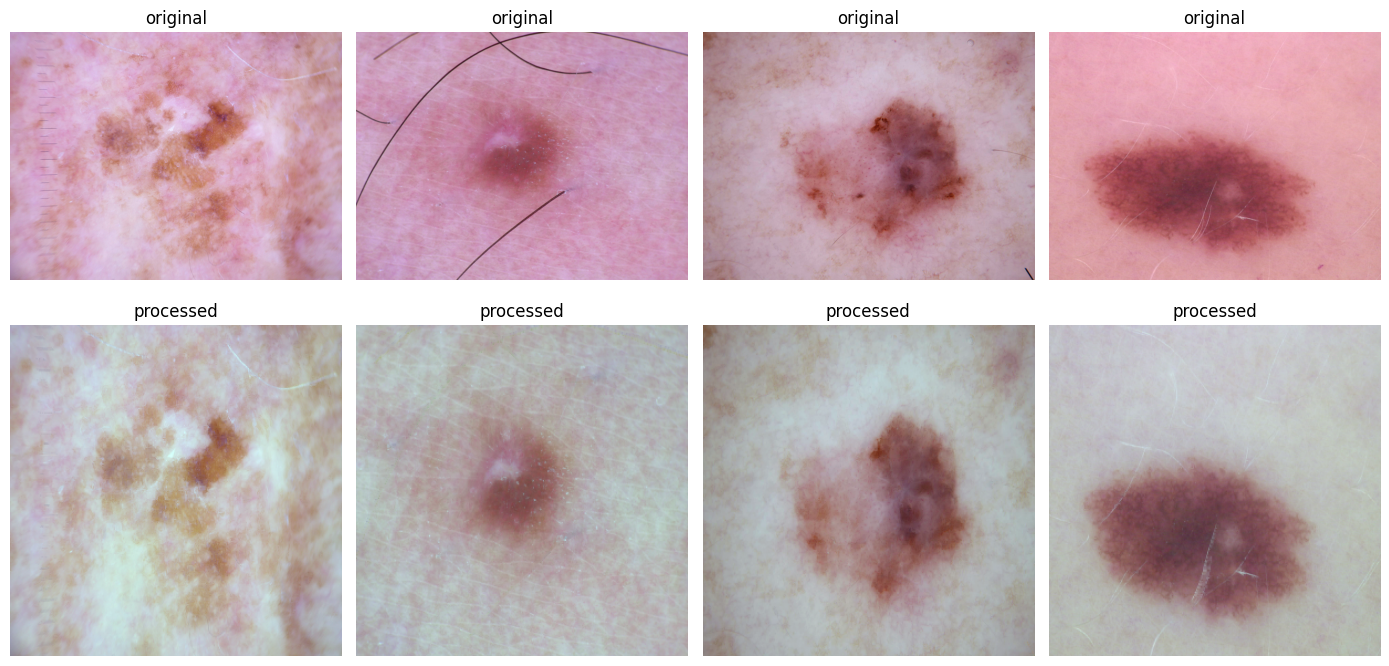

In [ ]:
# ===== 3. Pre-processing (hair removal + colour constancy), cached once in RAM =====
def remove_hair(img):
    # black-hat finds thin dark structures (hairs); inpaint fills them from the surrounding skin
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    return cv2.inpaint(img, mask, 1, cv2.INPAINT_TELEA)

def shades_of_gray(img, p=6):
    # removes the colour cast of the light source / camera so colours are comparable between images
    x = img.astype(np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p)
    illum = illum / (np.linalg.norm(illum) + 1e-8)
    x = x / (illum * np.sqrt(3.0) + 1e-8)
    return np.clip(x, 0, 255).astype(np.uint8)

def preprocess(path):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_AREA)
    if USE_HAIR_REMOVAL:    img = remove_hair(img)
    if USE_COLOR_CONSTANCY: img = shades_of_gray(img)
    return img

def build_cache(df, name):
    # processed images are stored as one uint8 array: fast training, no repeated slow Drive reads
    f = f"/content/cache_{name}_{IMG}_{int(USE_HAIR_REMOVAL)}{int(USE_COLOR_CONSTANCY)}.npy"
    if os.path.exists(f):
        return np.load(f)
    with ThreadPoolExecutor(8) as ex:
        imgs = list(tqdm(ex.map(preprocess, df["path"]), total=len(df), desc=f"caching {name}"))
    arr = np.stack(imgs)
    np.save(f, arr)
    return arr

train_imgs = build_cache(train_df, "train")
val_imgs   = build_cache(val_df, "val")
test_imgs  = build_cache(test_df, "test")
print(train_imgs.shape, val_imgs.shape, test_imgs.shape)

# quick visual check of the pre-processing
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for k in range(4):
    raw = cv2.cvtColor(cv2.imread(train_df["path"].iloc[k * 900]), cv2.COLOR_BGR2RGB)
    ax[0, k].imshow(raw);            ax[0, k].axis("off"); ax[0, k].set_title("original")
    ax[1, k].imshow(train_imgs[k * 900]); ax[1, k].axis("off"); ax[1, k].set_title("processed")
plt.tight_layout(); plt.show()


In [ ]:
# ===== 4. Augmentation, metadata features, dataset, balanced sampler =====
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(90),
    transforms.ColorJitter(0.25, 0.25, 0.25, 0.05),
    transforms.ToTensor(),
    norm,
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.1)),
])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])   # images are already resized

# ---- metadata: age, sex, body location (dx_type is NOT used: it leaks the label) ----
SEXES = ["male", "female", "unknown"]
LOCS = sorted(train_df["localization"].unique())
AGE_MEDIAN = train_df["age"].median()
META_DIM = 1 + len(SEXES) + len(LOCS)

def make_meta(df):
    age = (df["age"].fillna(AGE_MEDIAN).values / 100.0)[:, None]
    sex = np.stack([(df["sex"].values == s) for s in SEXES], 1)
    loc = np.stack([(df["localization"].values == l) for l in LOCS], 1)
    return np.concatenate([age, sex, loc], 1).astype(np.float32)

train_meta, val_meta, test_meta = make_meta(train_df), make_meta(val_df), make_meta(test_df)
train_labels = train_df["dx"].map(class_to_idx).values
val_labels   = val_df["dx"].map(class_to_idx).values
test_labels  = test_df["dx"].map(class_to_idx).values

class LesionDS(Dataset):
    def __init__(self, imgs, meta, labels, tf):
        self.imgs, self.meta, self.labels, self.tf = imgs, meta, labels, tf
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x = self.tf(Image.fromarray(self.imgs[i]))
        return x, torch.from_numpy(self.meta[i]), int(self.labels[i])

class EpochBalancedSampler(Sampler):
    """Re-drawn every epoch:
       class with more than TARGET images -> random subset of TARGET (undersampling, new subset each epoch)
       class with fewer than TARGET images -> all images + random repeats up to TARGET (oversampling)"""
    def __init__(self, labels, target, seed):
        self.target = target
        self.idx = {c: np.where(labels == c)[0] for c in np.unique(labels)}
        self.rng = np.random.RandomState(seed)
    def __iter__(self):
        out = []
        for c, ix in self.idx.items():
            if len(ix) >= self.target:
                out.append(self.rng.choice(ix, self.target, replace=False))
            else:
                extra = self.rng.choice(ix, self.target - len(ix), replace=True)
                out.append(np.concatenate([ix, extra]))
        out = np.concatenate(out)
        self.rng.shuffle(out)
        return iter(out.tolist())
    def __len__(self):
        return self.target * len(self.idx)

train_ds = LesionDS(train_imgs, train_meta, train_labels, train_tf)
val_ds   = LesionDS(val_imgs,   val_meta,   val_labels,   eval_tf)
test_ds  = LesionDS(test_imgs,  test_meta,  test_labels,  eval_tf)

val_loader  = DataLoader(val_ds,  BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, BATCH, shuffle=False, num_workers=2, pin_memory=True)
print("Metadata features:", META_DIM, "| samples per epoch:", TARGET * num_classes)


Metadata features: 19 | samples per epoch: 8400


In [ ]:
# ===== 5. Model (EfficientNet + metadata fusion), focal loss, EMA =====
class FusionNet(nn.Module):
    def __init__(self, arch, n_cls):
        super().__init__()
        if arch == "b3":
            self.backbone = efficientnet_b3(weights=EfficientNet_B3_Weights.DEFAULT)
        elif arch == "v2_s":
            self.backbone = efficientnet_v2_s(weights=EfficientNet_V2_S_Weights.DEFAULT)
        else:
            raise ValueError(arch)
        feat = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()                 # keep only the image features
        self.meta = nn.Sequential(nn.Linear(META_DIM, 64), nn.ReLU(), nn.Dropout(0.2))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(feat + 64, n_cls))
    def forward(self, x, m):
        return self.head(torch.cat([self.backbone(x), self.meta(m)], 1))

def focal_loss(logits, y, gamma=FOCAL_GAMMA, smooth=LABEL_SMOOTH):
    # focal term down-weights easy images; label smoothing reduces over-confidence.
    # No class weights here: the balanced sampler already equalises the classes.
    ce_smooth = F.cross_entropy(logits, y, reduction="none", label_smoothing=smooth)
    pt = torch.exp(-F.cross_entropy(logits, y, reduction="none")).detach()
    return ((1 - pt) ** gamma * ce_smooth).mean()

class ModelEMA:
    """Exponential moving average of the weights: smoother, usually better than the raw last weights."""
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        self.decay, self.n = decay, 0
        for p in self.module.parameters():
            p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))        # faster averaging at the start
        for e, m in zip(self.module.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(m.detach(), alpha=1 - d)
            else:
                e.copy_(m)


In [ ]:
# ===== 6. Prediction helpers (optional test-time augmentation) =====
@torch.no_grad()
def predict_probs(model, loader, tta=False):
    model.eval()
    P, Y = [], []
    for x, m, y in loader:
        x, m = x.to(device), m.to(device)
        views = [x] if not tta else [x, x.flip(3), x.flip(2), x.flip(2).flip(3)]   # orig, h-flip, v-flip, both
        with torch.autocast(device.type, dtype=torch.float16, enabled=(device.type == "cuda")):
            p = sum(F.softmax(model(v, m).float(), 1) for v in views) / len(views)
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def get_metrics(y, pred):
    return {"acc": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
            "bal_acc": balanced_accuracy_score(y, pred),
            "mel_recall": recall_score(y == MEL, pred == MEL, zero_division=0)}


In [7]:
# ===== 7. Train one model (best epoch chosen on VALIDATION macro-F1; test set is never used here) =====
def train_one(arch, seed):
    tag = f"{arch}_s{seed}"
    ckpt = os.path.join(SAVE_DIR, f"best_{tag}.pth")
    if os.path.exists(ckpt):
        print(f"[{tag}] checkpoint found, skipping training")
        return ckpt

    set_seed(seed)
    model = FusionNet(arch, num_classes).to(device)
    ema = ModelEMA(model, EMA_DECAY)

    sampler = EpochBalancedSampler(train_labels, TARGET, seed)
    loader = DataLoader(train_ds, BATCH, sampler=sampler, num_workers=2,
                        drop_last=True, pin_memory=True)

    opt = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": LR_BACKBONE},
        {"params": list(model.meta.parameters()) + list(model.head.parameters()), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.SequentialLR(
        opt,
        [torch.optim.lr_scheduler.LinearLR(opt, 0.1, 1.0, total_iters=WARMUP),
         torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS - WARMUP, eta_min=1e-6)],
        milestones=[WARMUP])
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    except AttributeError:
        scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))

    best_f1, bad, history = -1.0, 0, []
    for ep in range(EPOCHS):
        model.train()
        loss_sum, n = 0.0, 0
        for x, m, y in tqdm(loader, desc=f"[{tag}] epoch {ep+1}/{EPOCHS}", leave=False):
            x, m, y = x.to(device), m.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=(device.type == "cuda")):
                logits = model(x, m)
            loss = focal_loss(logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            ema.update(model)
            loss_sum += loss.item() * x.size(0); n += x.size(0)
        sched.step()

        P, Y = predict_probs(ema.module, val_loader)          # validate with the EMA weights
        r = get_metrics(Y, P.argmax(1))
        history.append({"epoch": ep + 1, "train_loss": loss_sum / n, **{f"val_{k}": v for k, v in r.items()}})
        print(f"[{tag}] ep {ep+1:02d} | loss {loss_sum/n:.4f} | val acc {r['acc']:.4f} "
              f"macroF1 {r['macro_f1']:.4f} balAcc {r['bal_acc']:.4f} melRecall {r['mel_recall']:.3f}")

        if r["macro_f1"] > best_f1:
            best_f1, bad = r["macro_f1"], 0
            torch.save(ema.module.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"[{tag}] early stop"); break

    pd.DataFrame(history).to_csv(os.path.join(SAVE_DIR, f"history_{tag}.csv"), index=False)
    print(f"[{tag}] best val macro-F1: {best_f1:.4f}")
    del model, ema, opt
    torch.cuda.empty_cache()
    return ckpt

# train every model of the ensemble (long run: each model takes a while on Colab; checkpoints go to Drive,
# so if the session disconnects just re-run this cell and finished models are skipped)
ckpts = [train_one(arch, seed) for arch, seed in ENSEMBLE]


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 151MB/s]


[b3_s42] epoch 1/30:   0%|          | 0/262 [00:00<?, ?it/s]

[b3_s42] ep 01 | loss 1.0902 | val acc 0.6002 macroF1 0.4678 balAcc 0.5939 melRecall 0.556


[b3_s42] epoch 2/30:   0%|          | 0/262 [00:00<?, ?it/s]

[b3_s42] ep 02 | loss 0.4512 | val acc 0.7173 macroF1 0.5723 balAcc 0.6120 melRecall 0.613


... (139 outputs left out)

[v2_s_s123] epoch 15/30:   0%|          | 0/262 [00:00<?, ?it/s]

[v2_s_s123] ep 15 | loss 0.0447 | val acc 0.8224 macroF1 0.6801 balAcc 0.6612 melRecall 0.839


[v2_s_s123] epoch 16/30:   0%|          | 0/262 [00:00<?, ?it/s]

[v2_s_s123] ep 16 | loss 0.0390 | val acc 0.8115 macroF1 0.6695 balAcc 0.6590 melRecall 0.823
[v2_s_s123] early stop
[v2_s_s123] best val macro-F1: 0.6989


Tuned class bias: {'akiec': np.float64(0.8), 'bcc': np.float64(0.4), 'bkl': np.float64(0.1), 'df': np.float64(1.0), 'mel': np.float64(-1.0), 'nv': np.float64(-0.1), 'vasc': np.float64(0.9)}


,acc,macro_f1,bal_acc,mel_recall
model,,,,
b3_s42,0.8002,0.6748,0.6868,0.7589
b3_s7,0.8189,0.7183,0.7095,0.7589
v2_s_s123,0.7933,0.7236,0.7524,0.7857
ENSEMBLE (TTA),0.8228,0.7034,0.7091,0.7411
ENSEMBLE (TTA + bias),0.8356,0.7325,0.7596,0.4554
ENSEMBLE (TTA + lesion avg),0.8287,0.7263,0.7261,0.7232



Single models (mean +- std over 3): macro-F1 0.7055 +- 0.0268 | acc 0.8041 +- 0.0132

=== Ensemble (TTA) classification report on TEST ===
              precision    recall  f1-score   support

       akiec       0.76      0.32      0.45        41
         bcc       0.82      0.83      0.83        54
         bkl       0.60      0.87      0.71       110
          df       0.80      0.40      0.53        10
         mel       0.52      0.74      0.61       112
          nv       0.96      0.86      0.91       673
        vasc       0.83      0.94      0.88        16

    accuracy                           0.82      1016
   macro avg       0.76      0.71      0.70      1016
weighted avg       0.86      0.82      0.83      1016



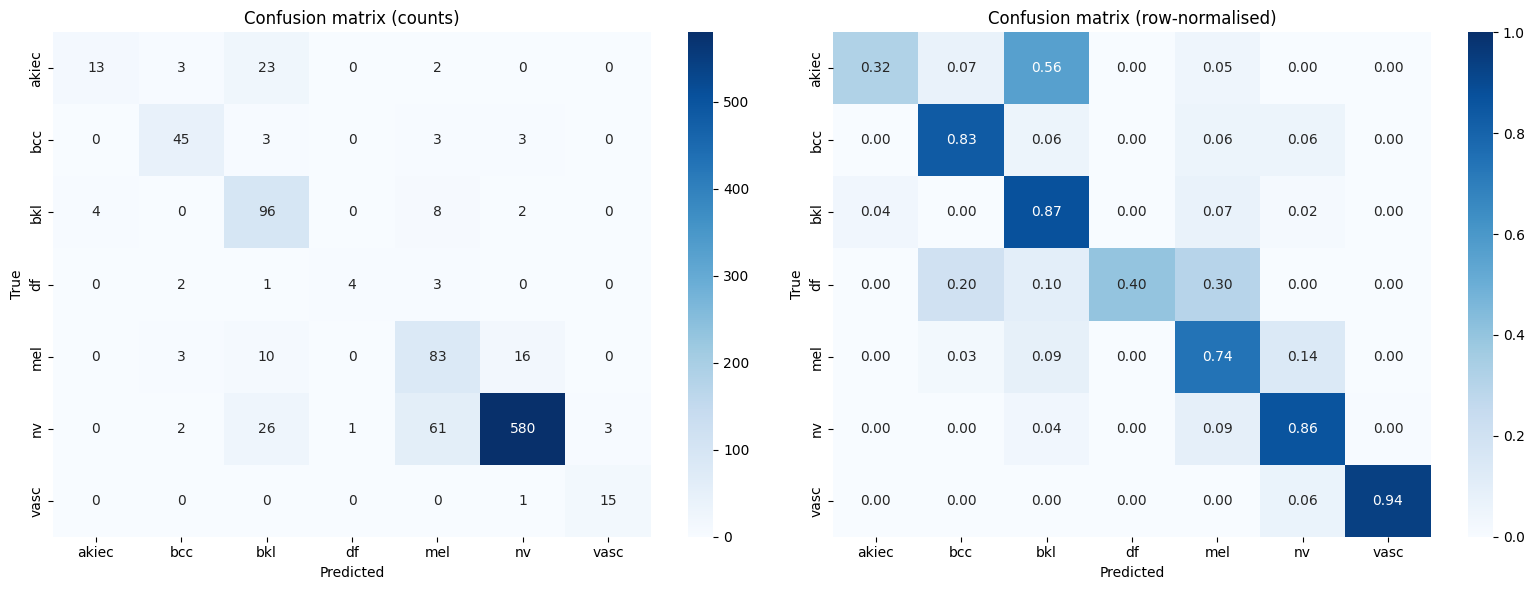

Saved results to: /content/drive/MyDrive/HAM10000_Project


In [8]:
# ===== 8. Final evaluation: single models, ensemble, bias tuning, lesion-level averaging =====
val_P, test_P, rows = [], [], []
for (arch, seed), ck in zip(ENSEMBLE, ckpts):
    model = FusionNet(arch, num_classes).to(device)
    model.load_state_dict(torch.load(ck, map_location=device))
    pv, yv = predict_probs(model, val_loader, tta=True)
    pt, yt = predict_probs(model, test_loader, tta=True)
    val_P.append(pv); test_P.append(pt)
    rows.append({"model": f"{arch}_s{seed}", **get_metrics(yt, pt.argmax(1))})
    del model; torch.cuda.empty_cache()

# ---- plain ensemble: average the probabilities of all models ----
ens_val, ens_test = np.mean(val_P, 0), np.mean(test_P, 0)
rows.append({"model": "ENSEMBLE (TTA)", **get_metrics(yt, ens_test.argmax(1))})

# ---- per-class bias tuned on VALIDATION only (fixes e.g. mel precision / recall balance).
#      Val has very few df / vasc images, so treat this row as optional and check it against the plain ensemble.
def tune_bias(probs, y, grid=np.linspace(-1, 1, 21), rounds=2):
    logp, bias = np.log(probs + 1e-8), np.zeros(probs.shape[1])
    for _ in range(rounds):
        for c in range(probs.shape[1]):
            best_b = bias[c]
            best_s = f1_score(y, (logp + bias).argmax(1), average="macro")
            for b in grid:
                t = bias.copy(); t[c] = b
                s = f1_score(y, (logp + t).argmax(1), average="macro")
                if s > best_s: best_s, best_b = s, b
            bias[c] = best_b
    return bias

bias = tune_bias(ens_val, yv)
print("Tuned class bias:", dict(zip(class_names, bias.round(2))))
pred_bias = (np.log(ens_test + 1e-8) + bias).argmax(1)
rows.append({"model": "ENSEMBLE (TTA + bias)", **get_metrics(yt, pred_bias)})

# ---- lesion-level averaging: images of the same lesion share one prediction (report separately) ----
def lesion_average(df, probs):
    p = pd.DataFrame(probs)
    p["lesion"] = df["lesion_id"].values
    return p.groupby("lesion").transform("mean").values
rows.append({"model": "ENSEMBLE (TTA + lesion avg)", **get_metrics(yt, lesion_average(test_df, ens_test).argmax(1))})

results = pd.DataFrame(rows).set_index("model")
display(results.round(4))

single = results.iloc[:len(ENSEMBLE)]
print(f"\nSingle models (mean +- std over {len(ENSEMBLE)}): "
      f"macro-F1 {single.macro_f1.mean():.4f} +- {single.macro_f1.std():.4f} | "
      f"acc {single.acc.mean():.4f} +- {single.acc.std():.4f}")

# ---- detailed report of the ensemble ----
final_pred = ens_test.argmax(1)
print("\n=== Ensemble (TTA) classification report on TEST ===")
print(classification_report(yt, final_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(yt, final_pred, labels=list(range(num_classes)))
cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=ax[1])
for a, t in zip(ax, ["Confusion matrix (counts)", "Confusion matrix (row-normalised)"]):
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(t)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "ensemble_confusion_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

# ---- save results + predictions so teammates can compare ----
results.to_csv(os.path.join(SAVE_DIR, "results_summary.csv"))
out = test_df[["lesion_id", "image_id", "dx"]].copy()
out["pred"] = [class_names[i] for i in final_pred]
for i, c in enumerate(class_names):
    out[f"p_{c}"] = ens_test[:, i]
out.to_csv(os.path.join(SAVE_DIR, "test_predictions.csv"), index=False)
print("Saved results to:", SAVE_DIR)


In [9]:
# ===== 9. Train / Val / Test scores of the best model, then save the model to Drive =====
# (run after cells 1-8; uses val_P, test_P, yv, yt, ens_val, ens_test, bias from cell 8)
train_eval_loader = DataLoader(LesionDS(train_imgs, train_meta, train_labels, eval_tf),
                               BATCH, shuffle=False, num_workers=2, pin_memory=True)

# training-set predictions: original (not resampled) training images, no augmentation, same TTA as val/test
train_P = []
for (arch, seed), ck in zip(ENSEMBLE, ckpts):
    model = FusionNet(arch, num_classes).to(device)
    model.load_state_dict(torch.load(ck, map_location=device))
    p, ytr = predict_probs(model, train_eval_loader, tta=True)
    train_P.append(p)
    del model; torch.cuda.empty_cache()
ens_train = np.mean(train_P, 0)

# best single model = highest VALIDATION macro-F1 (chosen on validation, never on test)
val_f1s = [f1_score(yv, p.argmax(1), average="macro") for p in val_P]
b = int(np.argmax(val_f1s))
best_arch, best_seed = ENSEMBLE[b]
best_tag = f"{best_arch}_s{best_seed}"

def split_row(name, ptr, pva, pte):
    r = {"model": name}
    for split, p, y in [("train", ptr, ytr), ("val", pva, yv), ("test", pte, yt)]:
        m = get_metrics(y, p.argmax(1))
        r[f"{split}_acc"] = m["acc"]
        r[f"{split}_macro_f1"] = m["macro_f1"]
    return r

final_table = pd.DataFrame([
    split_row(f"BEST SINGLE ({best_tag})", train_P[b], val_P[b], test_P[b]),
    split_row("ENSEMBLE (all models)", ens_train, ens_val, ens_test),
]).set_index("model")
display(final_table.round(4))
# a much higher train score than val/test score means the model is overfitting

# ---- save the final models to Drive (weights + everything needed to use them later) ----
common = {
    "class_names": class_names, "class_to_idx": class_to_idx, "img_size": IMG,
    "sexes": SEXES, "localizations": LOCS, "age_median": float(AGE_MEDIAN),
    "preprocessing": {"hair_removal": USE_HAIR_REMOVAL, "color_constancy": USE_COLOR_CONSTANCY},
    "normalize_mean": [0.485, 0.456, 0.406], "normalize_std": [0.229, 0.224, 0.225],
}
best_path = os.path.join(SAVE_DIR, "best_model.pth")
ens_path  = os.path.join(SAVE_DIR, "ensemble_model.pth")
csv_path  = os.path.join(SAVE_DIR, "train_val_test_scores.csv")

torch.save({**common, "arch": best_arch, "seed": best_seed,
            "state_dict": torch.load(ckpts[b], map_location="cpu"),
            "metrics": {k: float(v) for k, v in final_table.iloc[0].items()}}, best_path)

torch.save({**common, "class_bias": bias.tolist(),
            "members": [{"arch": a, "seed": s, "state_dict": torch.load(ck, map_location="cpu")}
                        for (a, s), ck in zip(ENSEMBLE, ckpts)],
            "metrics": {k: float(v) for k, v in final_table.iloc[1].items()}}, ens_path)

final_table.to_csv(csv_path)
for pth in (best_path, ens_path, csv_path):
    print(f"saved: {pth}  ({os.path.getsize(pth) / 1e6:.1f} MB)")

# ---- optional: also download the best single model + scores to your computer ----
DOWNLOAD_TO_PC = True
if DOWNLOAD_TO_PC:
    from google.colab import files
    files.download(best_path)
    files.download(csv_path)

# To load the best model later:
#   ck = torch.load(best_path, map_location="cpu")
#   model = FusionNet(ck["arch"], len(ck["class_names"])); model.load_state_dict(ck["state_dict"])

,train_acc,train_macro_f1,val_acc,val_macro_f1,test_acc,test_macro_f1
model,,,,,,
BEST SINGLE (b3_s42),0.9377,0.9550,0.8274,0.6866,0.8002,0.6748
ENSEMBLE (all models),0.9509,0.9656,0.8274,0.6876,0.8228,0.7034


saved: /content/drive/MyDrive/HAM10000_Project/best_model.pth  (43.4 MB)
saved: /content/drive/MyDrive/HAM10000_Project/ensemble_model.pth  (168.5 MB)
saved: /content/drive/MyDrive/HAM10000_Project/train_val_test_scores.csv  (0.0 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>